# Введение в Machine Learning
 Практические задания на основе набора данных Iris и Intel® oneAPI AI Analytics Toolkit (AI Kit).

### Упражнение 1: Загрузка и первичный анализ данных
    Используя библиотеки `pandas` и `numpy`, загрузите файл `Iris_Data.csv` из директории `data`. Выведите на экран:
    - Общее количество строк.
    - Имена всех колонок.
    - Типы данных для каждой колонки.

In [1]:
import os
import numpy as np
import pandas as pd

# Показывать все 36 колонок, а не первые 20
pd.set_option('display.max_columns', None)

# Датасет лежит в папке archive рядом с ноутбуком
data_dir = 'archive'
if not os.path.isdir(data_dir):
    import kagglehub
    data_dir = kagglehub.dataset_download('razanihababdellatif/coffee-quality-and-pricing-benchmark')

filepath = os.path.join(data_dir, 'coffee_value_benchmark.csv')
data = pd.read_csv(filepath)
data.head()

/home/conzoad/Projects/USM/Învățare automată/lab1/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,record_id,lot_id,harvest_season,harvest_calendar_year,harvest_month,country_of_origin,farm_type,farm_size_hectares,tree_age_years,altitude_mean_meters,species,avg_temp_c,avg_annual_rainfall_mm,humidity_pct,processing_method,drying_method,drying_duration_days,storage_months,storage_conditions,bean_size_screen,moisture_pct,bean_density_g_ml,defect_rate_pct,traceability_level,certification,intended_buyer_segment,lot_size_kg,roast_level,acidity_score,sweetness_score,body_score,aroma_score,flavor_score,coffee_quality_score,quality_grade,price_usd_per_kg
0,REC-0000001,LOT-0032936,2020/21,2020,10,Vietnam,Smallholder,0.58,28.0,1961.0,Arabica,16.9,2073.0,83.5,Natural,Mechanical,15.7,3,Basic,16,11.26,1.165,3.6,Country,NaN,Commodity,26433.0,Medium,7.95,7.30,8.45,7.35,7.37,78.01,Very Good,2.43
1,REC-0000002,LOT-0030952,2021/22,2022,1,Honduras,Smallholder,1.12,2.0,1257.0,Arabica,16.5,2059.0,NaN,Anaerobic,Patio,10.9,6,Basic,18,11.51,1.112,4.9,Country,NaN,Commodity,25446.0,Medium,7.62,8.17,7.45,7.80,6.88,75.62,Good,4.06
2,REC-0000003,LOT-0018572,2020/21,2020,11,Vietnam,Cooperative,13.82,5.0,557.0,Robusta,23.3,1973.0,74.8,Washed,Patio,10.8,4,Climate Controlled,19,NaN,1.094,0.0,Cooperative,NaN,Premium,15707.0,Medium,8.47,8.83,8.13,7.70,8.10,72.41,Commercial,4.26
3,REC-0000004,LOT-0005318,2021/22,2021,10,Vietnam,Cooperative,9.96,22.0,652.0,Robusta,24.6,2375.0,82.8,Washed,Patio,9.5,5,Basic,17,11.59,1.100,0.8,Cooperative,NaN,Commodity,2879.0,Medium,7.54,8.12,8.21,7.77,7.13,75.67,Good,3.60
4,REC-0000005,LOT-0006317,2021/22,2021,7,Brazil,Smallholder,1.90,11.0,971.0,Robusta,18.7,860.0,68.0,Honey,Patio,10.9,3,Basic,16,10.86,1.095,2.5,Country,NaN,Commodity,9561.0,Medium,6.70,8.08,8.68,7.38,7.16,73.77,Good,4.16


In [2]:
# Общее количество строк
print('Количество строк:', data.shape[0])

# Имена всех колонок
print('Количество колонок:', data.shape[1])
print(data.columns.tolist())

# Типы данных каждой колонки (текст: object в pandas 2, str в pandas 3)
print(data.dtypes)

Количество строк: 35700
Количество колонок: 36
['record_id', 'lot_id', 'harvest_season', 'harvest_calendar_year', 'harvest_month', 'country_of_origin', 'farm_type', 'farm_size_hectares', 'tree_age_years', 'altitude_mean_meters', 'species', 'avg_temp_c', 'avg_annual_rainfall_mm', 'humidity_pct', 'processing_method', 'drying_method', 'drying_duration_days', 'storage_months', 'storage_conditions', 'bean_size_screen', 'moisture_pct', 'bean_density_g_ml', 'defect_rate_pct', 'traceability_level', 'certification', 'intended_buyer_segment', 'lot_size_kg', 'roast_level', 'acidity_score', 'sweetness_score', 'body_score', 'aroma_score', 'flavor_score', 'coffee_quality_score', 'quality_grade', 'price_usd_per_kg']
record_id                     str
lot_id                        str
harvest_season                str
harvest_calendar_year       int64
harvest_month               int64
country_of_origin             str
farm_type                     str
farm_size_hectares        float64
tree_age_years   

### Упражнение 2: Очистка и преобразование текстовых данных
    Исследуйте значения в колонке `species`.
    Обратите внимание, что все они начинаются с префикса `Iris-`.
    Напишите код для удаления этого префикса во всех строках (чтобы осталось только `setosa`, `versicolor`, `virginica`).

In [3]:
# Колонка species в этом наборе уже чистая: префикса вроде «Iris-» у видов нет
print('Виды:', data['species'].unique().tolist())

# Одинаковый префикс есть у всех идентификаторов (аналог «Iris-»): REC- у записей и LOT- у лотов
print(data[['record_id', 'lot_id']].head(3))
print('Все record_id начинаются с "REC-":', data['record_id'].str.startswith('REC-').all())
print('Все lot_id начинаются с "LOT-":', data['lot_id'].str.startswith('LOT-').all())

Виды: ['Arabica', 'Robusta']
     record_id       lot_id
0  REC-0000001  LOT-0032936
1  REC-0000002  LOT-0030952
2  REC-0000003  LOT-0018572
Все record_id начинаются с "REC-": True
Все lot_id начинаются с "LOT-": True


In [4]:
# Удаляем префикс строковым методом .str.replace, как в примере с «Iris-»,
# и переводим оставшиеся номера в целые числа
data['record_id'] = data['record_id'].str.replace('REC-', '', regex=False).astype(int)
data['lot_id'] = data['lot_id'].str.replace('LOT-', '', regex=False).astype(int)
# Альтернатива через apply:
# data['lot_id'] = data['lot_id'].apply(lambda s: int(s.replace('LOT-', '')))

data[['record_id', 'lot_id', 'species']].head()

,record_id,lot_id,species
0,1,32936,Arabica
1,2,30952,Arabica
2,3,18572,Robusta
3,4,5318,Robusta
4,5,6317,Robusta


In [5]:
# Дополнительная очистка 1: в колонке certification строка "None" значит «нет сертификата»,
# но pandas по умолчанию читает её как пропуск (NaN). Возвращаем это значение.
print('Пропусков в certification до исправления:', data['certification'].isna().sum())
data['certification'] = data['certification'].fillna('None')
print(data['certification'].value_counts(), end='\n\n')

# Дополнительная очистка 2: удаляем точные дубликаты записей.
# Тип каждой записи берём из coffee_record_metadata.csv
meta = pd.read_csv(os.path.join(data_dir, 'coffee_record_metadata.csv'))
meta['record_id'] = meta['record_id'].str.replace('REC-', '', regex=False).astype(int)
data = data.merge(meta[['record_id', 'record_type']], on='record_id', how='left')
print(data['record_type'].value_counts(), end='\n\n')

# Повторные измерения (Measurement Revision) оставляем: значения в них отличаются от оригинала
data = data[data['record_type'] != 'Exact Duplicate'].drop(columns='record_type').reset_index(drop=True)
print('Строк после удаления точных дубликатов:', len(data))

Пропусков в certification до исправления: 21723
certification
None                   21723
Fair Trade              5900
Organic                 3638
Multiple                2807
Rainforest Alliance     1632
Name: count, dtype: int64

record_type
Original                35000
Measurement Revision      350
Exact Duplicate           350
Name: count, dtype: int64

Строк после удаления точных дубликатов: 35350


### Упражнение 3: Описательная статистика и размах (range)
    Используя метод `describe()`,
    создайте новую строку в таблице под названием `range`,
    которая вычисляет разницу между максимальным
    и минимальным значением для каждого числового столбца.

In [6]:
# Числовые признаки: все числовые колонки, кроме идентификаторов
num_cols = data.select_dtypes(include='number').columns.drop(['record_id', 'lot_id']).tolist()

stats_df = data[num_cols].describe()
# Новая строка range: разница между максимумом и минимумом
stats_df.loc['range'] = stats_df.loc['max'] - stats_df.loc['min']

# 22 признака удобнее читать транспонированными: признаки по строкам, статистики и range по столбцам
stats_df.T.round(2)

,count,mean,std,min,25%,50%,75%,max,range
harvest_calendar_year,35350.0,2021.47,1.28,2019.00,2021.00,2021.00,2022.00,2024.00,5.00
harvest_month,35350.0,8.09,3.23,1.00,6.00,9.00,11.00,12.00,11.00
farm_size_hectares,35350.0,16.59,37.42,0.35,1.57,2.75,14.99,920.26,919.91
tree_age_years,35350.0,15.14,8.01,2.00,9.00,14.00,19.00,50.00,48.00
altitude_mean_meters,35350.0,1145.19,531.52,150.00,692.00,1071.00,1616.00,2726.00,2576.00
avg_temp_c,35350.0,18.18,4.43,7.10,14.10,19.00,22.00,27.00,19.90
avg_annual_rainfall_mm,33554.0,1885.25,531.02,327.00,1453.00,1883.00,2304.00,3345.00,3018.00
humidity_pct,33092.0,74.54,6.10,55.90,69.80,74.25,79.40,93.30,37.40
drying_duration_days,35350.0,14.28,5.04,2.00,11.00,14.60,17.80,29.20,27.20
storage_months,35350.0,4.00,2.00,0.00,3.00,4.00,5.00,15.00,15.00


### Упражнение 4: Группировка данных по видам (Среднее и Медиана)
    "Сгруппируйте набор данных по колонке `species`
    и одновременно примените функции **среднего** (`mean`)
    и **медианы** (`median`) ко всем числовым колонкам.

In [7]:
# Одна группировка сразу с двумя функциями. Берём только числовые колонки:
# в pandas 2+ mean() и median() по текстовым колонкам вызывают ошибку
species_stats = data.groupby('species')[num_cols].agg(['mean', 'median'])

# Транспонируем для читаемости: строки — признак и статистика, столбцы — виды
species_stats.T.round(2)

species                         Arabica   Robusta
harvest_calendar_year  mean     2021.49   2021.43
                       median   2022.00   2021.00
harvest_month          mean        8.06      8.15
                       median      9.00      9.00
farm_size_hectares     mean       16.67     16.44
                       median      2.76      2.73
tree_age_years         mean       15.15     15.10
                       median     14.00     14.00
altitude_mean_meters   mean     1439.83    600.95
                       median   1479.00    599.00
avg_temp_c             mean       15.71     22.76
                       median     15.30     23.00
avg_annual_rainfall_mm mean     1798.61   2043.59
                       median   1694.00   2108.00
humidity_pct           mean       72.93     77.46
                       median     72.30     78.50
drying_duration_days   mean       14.51     13.86
                       median     15.00     13.90
storage_months         mean        4.01      3.98
                       median      4.00      4.00
bean_size_screen       mean       16.01     16.00
                       median     16.00     16.00
moisture_pct           mean       10.98     11.11
                       median     10.96     11.10
bean_density_g_ml      mean        1.15      1.07
                       median      1.15      1.07
defect_rate_pct        mean        2.73      2.85
                       median      2.50      2.60
lot_size_kg            mean    18043.33  18070.26
                       median  17482.00  17600.50
acidity_score          mean        8.21      6.88
                       median      8.23      6.83
sweetness_score        mean        8.20      7.34
                       median      8.21      7.33
body_score             mean        8.25      8.53
                       median      8.24      8.54
aroma_score            mean        7.91      7.03
                       median      7.91      7.03
flavor_score           mean        7.81      6.98
                       median      7.83      6.99
coffee_quality_score   mean       80.41     72.42
                       median     80.39     72.45
price_usd_per_kg       mean        5.37      3.77
                       median      4.65      3.61

### Упражнение 5: Расширенная агрегация с помощью словаря
    Используя метод `agg()` для сгруппированных данных,
    примените следующие правила: для `sepal_length`, `sepal_width` и `petal_width`
    вычислите среднее и медиану, а для `petal_length` — только максимальное значение (`max`).

In [8]:
from pprint import pprint

# Сенсорные оценки: среднее и медиана; итоговая оценка качества: только максимум
agg_dict = {col: ['mean', 'median'] for col in ['acidity_score', 'sweetness_score', 'body_score']}
agg_dict['coffee_quality_score'] = 'max'
pprint(agg_dict)

data.groupby('species').agg(agg_dict).round(2)

{'acidity_score': ['mean', 'median'],
 'body_score': ['mean', 'median'],
 'coffee_quality_score': 'max',
 'sweetness_score': ['mean', 'median']}


acidity_score        sweetness_score        body_score         \
                 mean median            mean median       mean median   
species                                                                 
Arabica          8.21   8.23            8.20   8.21       8.25   8.24   
Robusta          6.88   6.83            7.34   7.33       8.53   8.54   

        coffee_quality_score  
                         max  
species                       
Arabica                94.18  
Robusta                84.37

### Упражнение 6: Визуализация данных с помощью Matplotlib
    Импортируйте `matplotlib.pyplot`
    и постройте диаграмму рассеяния (scatter plot),
    отражающую зависимость `sepal_length` (ось X) от `sepal_width` (ось Y).
    Добавьте подписи осей и заголовок.

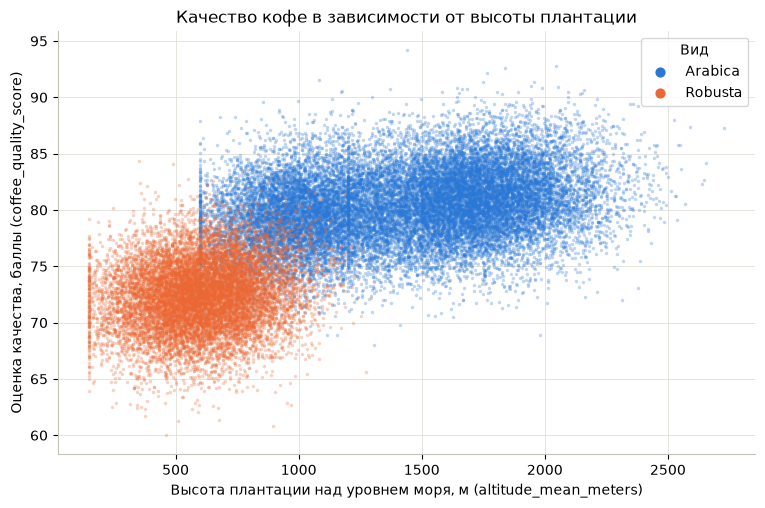

In [9]:
import matplotlib.pyplot as plt

# Светлая сетка под данными и без лишних рамок
plt.rcParams.update({
    'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#c3c2b7', 'axes.spines.top': False, 'axes.spines.right': False,
})
# Постоянные цвета видов для всех графиков ноутбука
species_colors = {'Arabica': '#2a78d6', 'Robusta': '#eb6834'}

fig, ax = plt.subplots(figsize=(9, 5.5))
for name, group in data.groupby('species'):
    ax.scatter(group['altitude_mean_meters'], group['coffee_quality_score'],
               s=6, alpha=0.3, linewidths=0, color=species_colors[name], label=name)

ax.set(xlabel='Высота плантации над уровнем моря, м (altitude_mean_meters)',
       ylabel='Оценка качества, баллы (coffee_quality_score)',
       title='Качество кофе в зависимости от высоты плантации')
legend = ax.legend(title='Вид', markerscale=3)
for handle in legend.legend_handles:
    handle.set_alpha(1)
plt.show()

### Упражнение 7: Подсчет частоты видов
    "Используйте специальный метод Pandas,
    чтобы узнать точное количество записей
    для каждого отдельного вида в очищенном наборе данных.

In [10]:
# value_counts() считает количество записей для каждого значения колонки
print(data['species'].value_counts(), end='\n\n')

# normalize=True даёт доли; переводим их в проценты
print((data['species'].value_counts(normalize=True) * 100).round(1))

species
Arabica    22934
Robusta    12416
Name: count, dtype: int64

species
Arabica    64.9
Robusta    35.1
Name: proportion, dtype: float64


### Упражнение 8: Ускорение Scikit-learn с помощью Intel® Extension
    Напишите строки кода, которые необходимо выполнить сразу
    после импорта библиотеки `sklearn` для включения оптимизации oneDAL.

In [11]:
import sklearn

try:
    # Две строки, которые включают оптимизации oneDAL (Intel® Extension for Scikit-learn)
    from sklearnex import patch_sklearn
    patch_sklearn()
    sklearnex_available = True
except ImportError:
    # Пакет не установлен: pip install scikit-learn-intelex
    sklearnex_available = False
    print('Intel® Extension for Scikit-learn не установлен, работает обычный scikit-learn')

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


In [12]:
import time
from sklearn.metrics import r2_score

# Демонстрация на наших данных: случайный лес прогнозирует coffee_quality_score.
# Разбиение по времени из coffee_benchmark_splits.csv: сезон 2023/24 — тест, ранние сезоны — обучение
splits = pd.read_csv(os.path.join(data_dir, 'coffee_benchmark_splits.csv'))
splits['lot_id'] = splits['lot_id'].str.replace('LOT-', '', regex=False).astype(int)
model_data = data.merge(splits, on='lot_id', how='left')

features = ['altitude_mean_meters', 'avg_temp_c', 'tree_age_years', 'farm_size_hectares',
            'drying_duration_days', 'storage_months', 'bean_size_screen', 'defect_rate_pct']
is_train = model_data['temporal_split'] == 'Train'
X_train, y_train = model_data.loc[is_train, features], model_data.loc[is_train, 'coffee_quality_score']
X_test, y_test = model_data.loc[~is_train, features], model_data.loc[~is_train, 'coffee_quality_score']

def train_forest():
    # Импорт внутри функции берёт текущую версию класса: обычную или оптимизированную
    from sklearn.ensemble import RandomForestRegressor
    model = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
    start = time.perf_counter()
    model.fit(X_train, y_train)
    seconds = time.perf_counter() - start
    return {'модуль класса': type(model).__module__,
            'обучение, с': round(seconds, 2),
            'R² на тесте': round(r2_score(y_test, model.predict(X_test)), 3)}

results = {}
if sklearnex_available:
    from sklearnex import unpatch_sklearn
    unpatch_sklearn()  # на время замера возвращаем обычный scikit-learn
    results['scikit-learn'] = train_forest()
    patch_sklearn(verbose=False)
    results['scikit-learn + sklearnex'] = train_forest()
else:
    results['scikit-learn'] = train_forest()

pd.DataFrame(results).T

,модуль класса,"обучение, с",R² на тесте
scikit-learn,sklearn.ensemble._forest,2.16,0.586
scikit-learn + sklearnex,sklearnex.ensemble._forest,0.91,0.586


### Упражнение 9: Фреймворки в Machine Learning
    Основываясь на вводных материалах, объясните,
    почему фреймворки — это больше, чем просто библиотеки,
    и какую материальную пользу приносит оптимизация гиперпараметров.

#### Напишите ваш ответ в виде текстовой ячейки или комментария

**Ответ.**

**Почему фреймворк — больше, чем библиотека.** Библиотека — это набор готовых функций и классов, которые вызывает ваш код: вы сами решаете, что и когда вызвать, и управляете ходом программы. Фреймворк, кроме вызываемого кода, задаёт структуру и правила, то есть влияет на то, *как* пишется код. Например, в scikit-learn все модели устроены одинаково: объект-оценщик с методами `fit`, `predict`, `transform`, которые можно собирать в `Pipeline` и настраивать через `GridSearchCV`. Поэтому код получается единообразным, модели легко заменять друг на друга, а обучение, проверка и подбор параметров строятся по одной схеме.

**Материальная польза оптимизации гиперпараметров.** Оптимизированный фреймворк (например, scikit-learn с Intel® Extension for Scikit-learn на базе oneDAL) выполняет тот же код быстрее. Для одной модели ускорение — просто удобство. Но подбор гиперпараметров (`GridSearchCV`, `RandomizedSearchCV`) требует обучить десятки и сотни моделей, часто с кросс-валидацией, и тогда ускорение даёт материальный выигрыш:

- за то же время на том же оборудовании можно перебрать больше комбинаций гиперпараметров и фолдов и найти более точную модель;
- снижаются затраты на вычисления: процессорное время, облачные ресурсы, электроэнергия;
- быстрее проходит цикл экспериментов: гипотеза проверяется за минуты, а не за часы, и модель можно чаще переобучать на свежих данных.

Итог: оптимизация даёт не только скорость, но и более качественную модель при тех же ресурсах.

### Упражнение 10: Предварительные требования курса
    Перечислите как минимум три базовых направления
    (в математике и программировании),
    необходимых для успешного прохождения курса по Machine Learning.

#### Напишите ваш ответ в виде текстовой ячейки или комментария

**Ответ.** Во вводных материалах (раздел «Требования к слушателям») названы четыре направления:

1. **Программирование на Python** — синтаксис, функции, структуры данных и работа с библиотеками NumPy, Pandas, Matplotlib, Seaborn, scikit-learn.
2. **Математический анализ** — производные, градиенты, поиск минимума функции. На этом построено обучение моделей: градиентный спуск минимизирует функцию потерь.
3. **Линейная алгебра** — векторы, матрицы, матричное умножение. Данные хранятся как матрица «объекты × признаки», а многие модели (линейная регрессия, метод главных компонент) записываются в матричном виде.
4. **Статистика** — распределения, среднее, медиана, дисперсия, корреляция, проверка гипотез. Она нужна для анализа данных и оценки качества моделей.

## Упражнение 11: Продвинутая визуализация распределений с Matplotlib (Гистограммы)
    Используя Matplotlib, постройте фигуру с двумя подграфиками (subplots)
    рядом друг с другом (1 строка, 2 колонки):,
    - На первом графике отобразите гистограмму распределения для `petal_length`.,
    - На втором графике отобразите гистограмму распределения для `petal_width`.,
    Добавьте заголовки и подписи к осям для каждого графика.

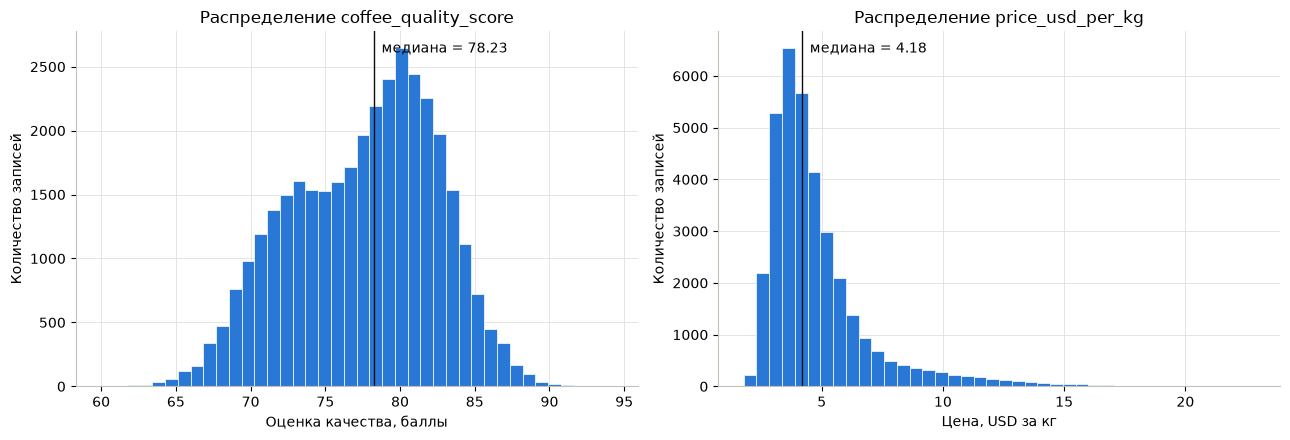

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Первый график: распределение итоговой оценки качества
ax1.hist(data['coffee_quality_score'], bins=40, color='#2a78d6', edgecolor='white', linewidth=0.5)
ax1.set(xlabel='Оценка качества, баллы', ylabel='Количество записей',
        title='Распределение coffee_quality_score')

# Второй график: распределение цены
ax2.hist(data['price_usd_per_kg'], bins=40, color='#2a78d6', edgecolor='white', linewidth=0.5)
ax2.set(xlabel='Цена, USD за кг', ylabel='Количество записей',
        title='Распределение price_usd_per_kg')

# Медиана на каждом графике
for ax, col in [(ax1, 'coffee_quality_score'), (ax2, 'price_usd_per_kg')]:
    median = data[col].median()
    ax.axvline(median, color='#0b0b0b', linewidth=1)
    ax.text(median, 0.97, f'  медиана = {median:.2f}', transform=ax.get_xaxis_transform(), va='top')

plt.tight_layout()
plt.show()

### Упражнение 12: Исследование данных с помощью Seaborn (Pairplot)
    Импортируйте библиотеку `seaborn`
    и постройте парную матрицу графиков (`sns.pairplot`)
    для всего набора данных Iris,
    раскрасив точки в зависимости от вида растения (`species`).

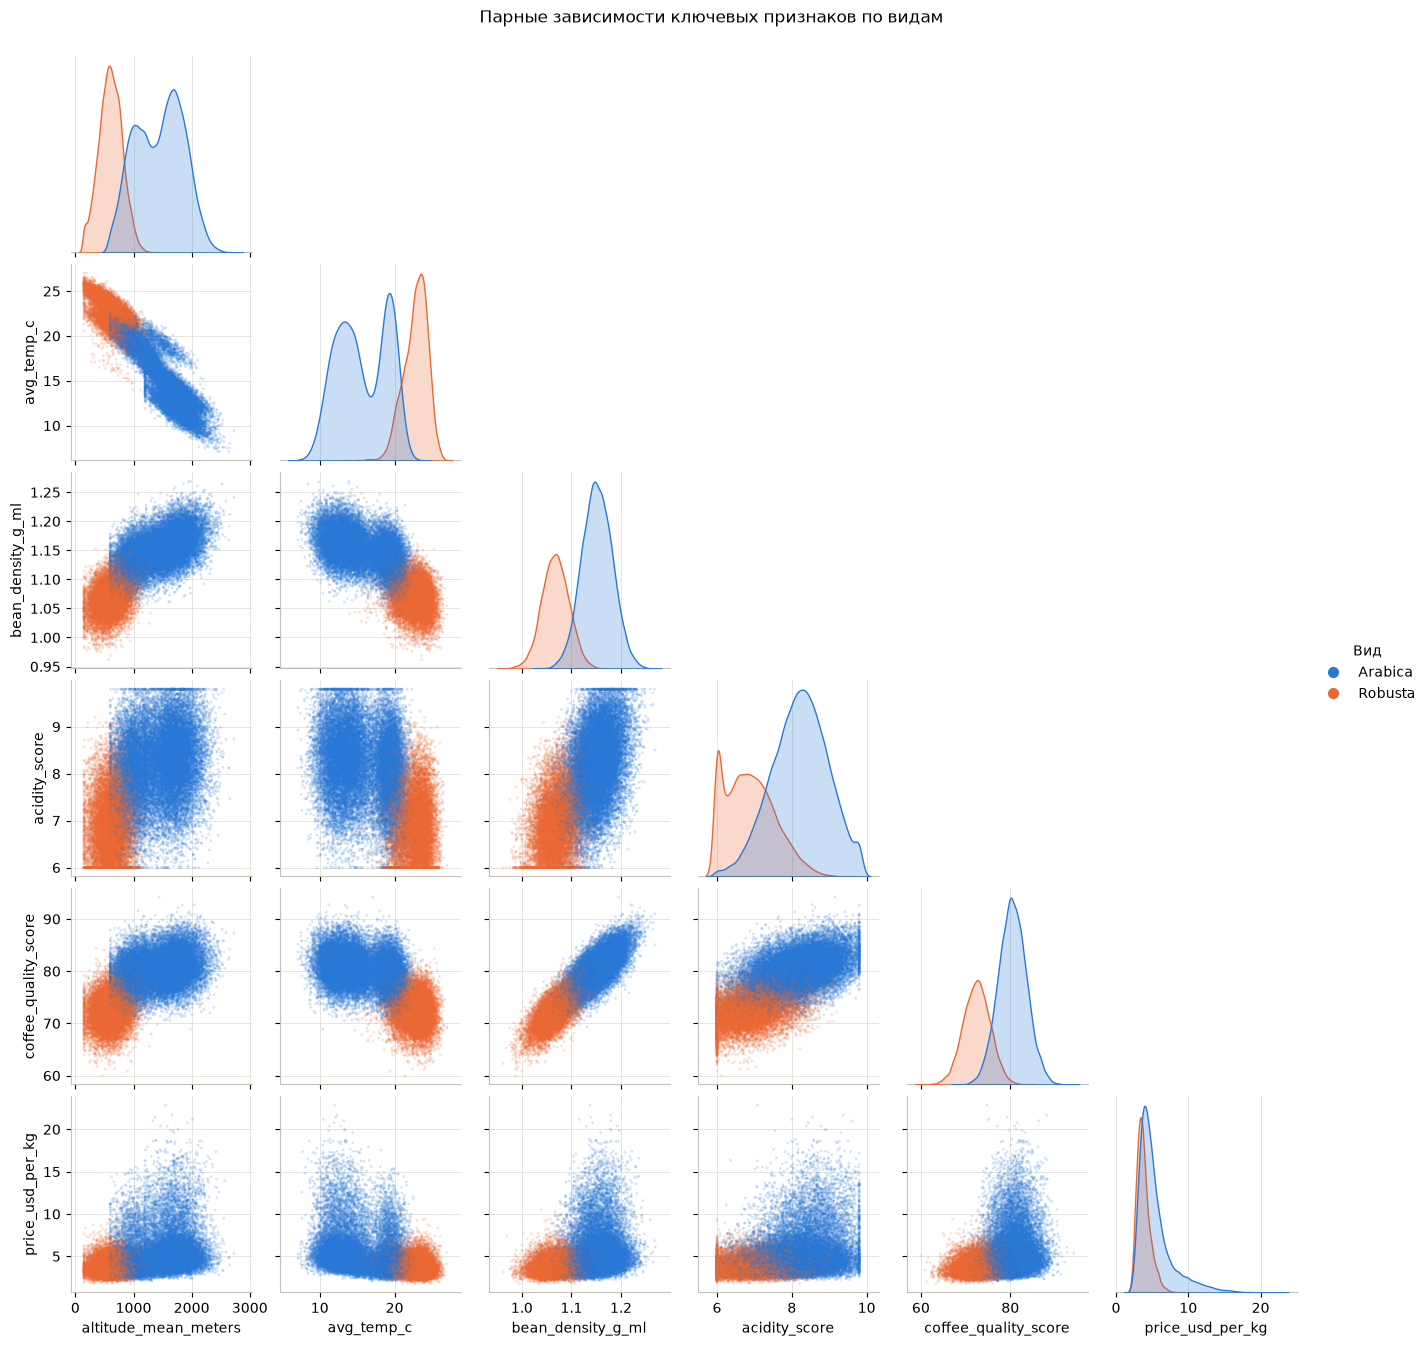

In [14]:
import seaborn as sns

# Все 22 числовых признака дали бы 22 × 22 = 484 графика, поэтому берём 6 ключевых
pair_cols = ['altitude_mean_meters', 'avg_temp_c', 'bean_density_g_ml',
             'acidity_score', 'coffee_quality_score', 'price_usd_per_kg']

grid = sns.pairplot(data, vars=pair_cols, hue='species', hue_order=['Arabica', 'Robusta'],
                    palette=species_colors, corner=True, height=2.2,
                    plot_kws={'s': 4, 'alpha': 0.2, 'linewidth': 0})
grid.figure.suptitle('Парные зависимости ключевых признаков по видам', y=1.02)

# Маркеры легенды наследуют прозрачность и размер точек, делаем их заметными
grid.legend.set_title('Вид')
for handle in grid.legend.legend_handles:
    handle.set_alpha(1)
    handle.set_markersize(8)
plt.show()

### Упражнение 13: Анализ выбросов через Boxplot (Seaborn)
    Используя библиотеку Seaborn, постройте график «ящик с усами» (`sns.boxplot`),
    чтобы сравнить распределение длины лепестков (`petal_length`) для каждого отдельного вида (`species`).

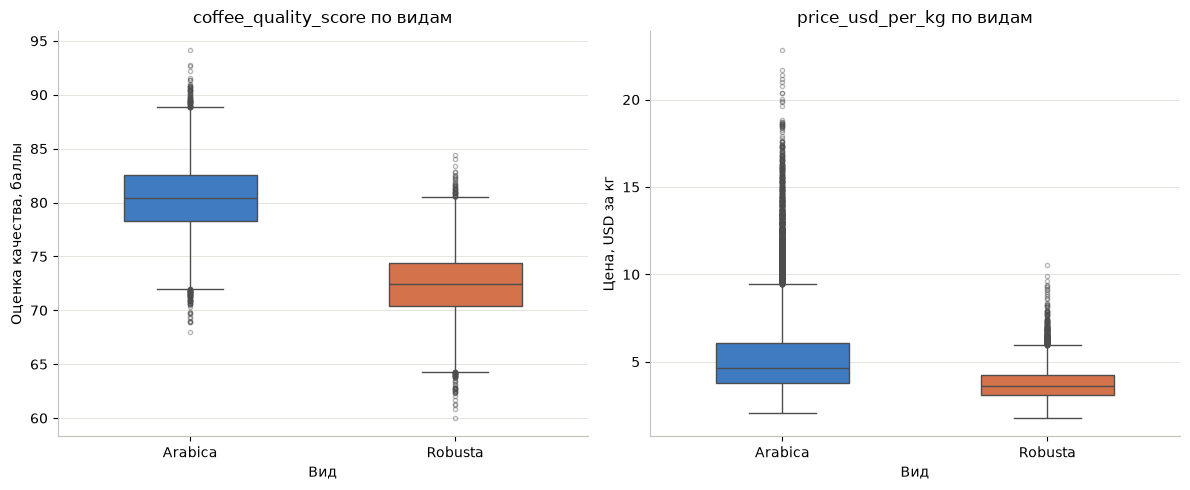

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
box_style = dict(hue='species', order=['Arabica', 'Robusta'], palette=species_colors, legend=False,
                 width=0.5, flierprops={'markersize': 3, 'alpha': 0.4})

# График задания: оценка качества по видам
sns.boxplot(data=data, x='species', y='coffee_quality_score', ax=ax1, **box_style)
ax1.set(xlabel='Вид', ylabel='Оценка качества, баллы', title='coffee_quality_score по видам')

# Для сравнения: цена, у которой выбросов гораздо больше
sns.boxplot(data=data, x='species', y='price_usd_per_kg', ax=ax2, **box_style)
ax2.set(xlabel='Вид', ylabel='Цена, USD за кг', title='price_usd_per_kg по видам')

plt.tight_layout()
plt.show()

In [16]:
# Выбросы по правилу «усов»: значения дальше 1.5 × IQR от первого и третьего квартилей
def count_outliers(values):
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum()

box_cols = ['coffee_quality_score', 'price_usd_per_kg']
outlier_counts = data.groupby('species')[box_cols].agg(count_outliers)
outlier_share = outlier_counts.div(data['species'].value_counts(), axis=0).mul(100).round(1)
pd.concat({'выбросов, шт.': outlier_counts, 'выбросов, %': outlier_share}, axis=1)

выбросов, шт.                           выбросов, %  \
        coffee_quality_score price_usd_per_kg coffee_quality_score   
species                                                              
Arabica                  161             1791                  0.7   
Robusta                  101              351                  0.8   

                          
        price_usd_per_kg  
species                   
Arabica              7.8  
Robusta              2.8

### Упражнение 14: Тепловая карта корреляций (Seaborn Heatmap)
    Вычислите корреляционную матрицу числовых признаков
    с помощью метода `corr()`, а затем визуализируйте её в виде тепловой карты (`sns.heatmap`),
    включив отображение числовых значений внутри ячеек (`annot=True`).

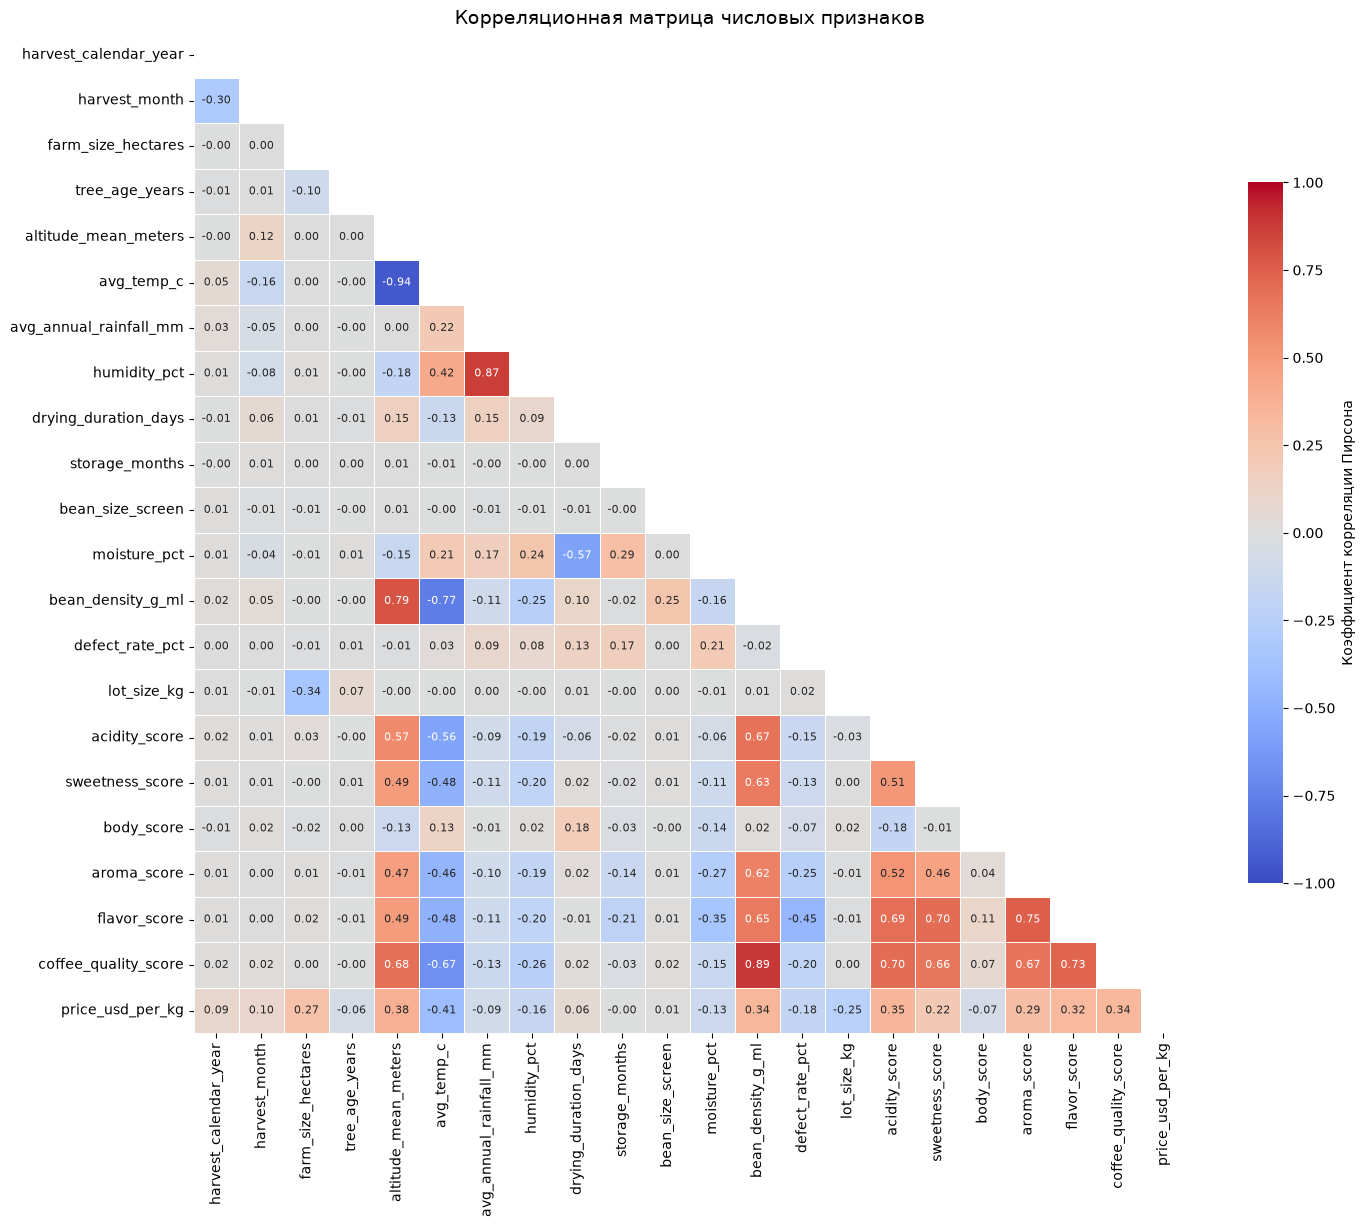

In [17]:
corr = data[num_cols].corr()

# Верхний треугольник и диагональ повторяют нижний треугольник, поэтому скрываем их
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', annot_kws={'size': 8},
            cmap='coolwarm', vmin=-1, vmax=1, center=0, linewidths=0.5,
            cbar_kws={'shrink': 0.7, 'label': 'Коэффициент корреляции Пирсона'}, ax=ax)
ax.grid(False)
ax.set_title('Корреляционная матрица числовых признаков', fontsize=14)
plt.show()

## Выводы

- После очистки осталось 35 350 записей из 35 700: удалены 350 точных дубликатов, у идентификаторов убраны префиксы `REC-` и `LOT-`, в `certification` восстановлено значение `None`. В четырёх признаках (осадки, влажность воздуха, влажность и плотность зерна) не хватает от 4.5 до 6.4% значений.
- Arabica — 22 934 записи (64.9%), Robusta — 12 416 (35.1%).
- Виды заметно различаются. Arabica растёт выше (медиана 1 479 м против 599 м) и в более прохладном климате (15.3 °C против 23.0 °C), получает более высокую оценку качества (в среднем 80.4 против 72.4 балла) и стоит дороже (медиана 4.65 против 3.61 USD/кг). Из сенсорных оценок Robusta выше только по «телу» напитка (`body_score` 8.53 против 8.25).
- Оценки качества сосредоточены вокруг медианы 78.23 балла, а «плечо» слева, около 72–75 баллов, образуют лоты Robusta. Цена скошена вправо: медиана 4.18 USD/кг, максимум 22.85 USD/кг.
- Выбросов в оценке качества мало: 0.7–0.8% записей каждого вида. В цене их намного больше: 7.8% лотов Arabica (1 791) и 2.8% лотов Robusta (351). Это длинный хвост дорогих партий.
- С качеством сильнее всего связаны плотность зерна (r = 0.89), высота плантации (0.68), температура (−0.67) и сенсорные оценки (0.66–0.73, кроме `body_score` с 0.07). Высота и температура сильно связаны между собой (r = −0.94): чем выше плантация, тем прохладнее. Цена связана с качеством слабо (r = 0.34), значит, на неё влияют и другие факторы.
- В упражнении 8 Intel® Extension for Scikit-learn обучил тот же случайный лес примерно в 3 раза быстрее обычного scikit-learn при той же точности (R² = 0.586). Точное время обучения зависит от компьютера.